# Домашняя работа: Теория Вероятностей
## Выполнил: Казимиров Егор

# 2. Симуляции в Python

## Задание 2.1. Нормальная выборка

In [1]:
# сначала импортирую нужные библиотеки
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# генерирую выборку
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)

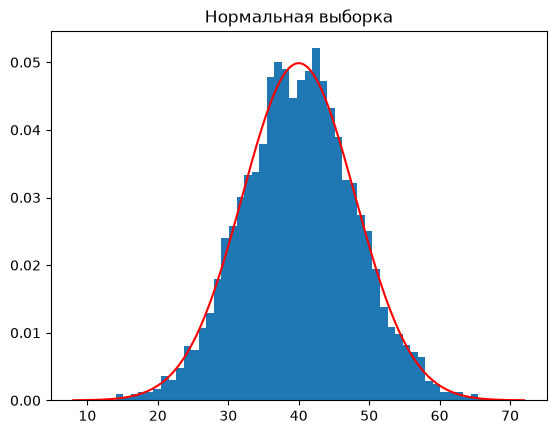

In [38]:
# и строю график
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color='red')
plt.title('Нормальная выборка')
plt.show()

In [4]:
# и сравниваю характеристики
print(sample.mean(), sample.std())

40.0448931070765 7.969326317621993


**Вывод:**
Гистограмма визуально совпала с теоретической плотностью - форма колокола такая же. Выборочные среднее (40.04) и стандартное отклонение (7.97) практически совпали с заданными 40 и 8. Небольшое отклонение ожидаемо, потому что 5000 - это хорошая, но все же конечная выборка.

## Задание 2.2. Биномиальная выборка

In [5]:
# генерирую выборку
n, p = 1000, 0.04
sample_bin = np.random.binomial(n, p, size=5000)

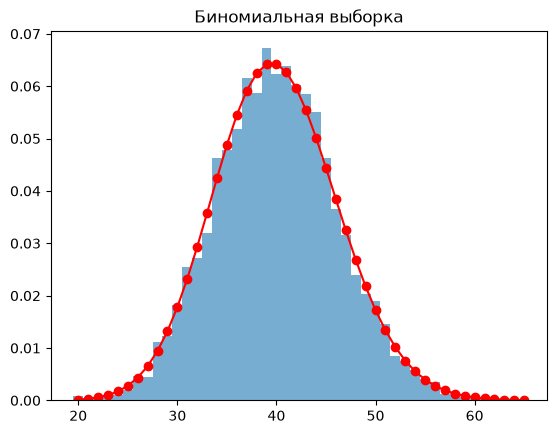

In [16]:
# строю график
k = np.arange(sample_bin.min(), sample_bin.max() + 1)

plt.hist(sample_bin, bins=k - 0.5, density=True, alpha=0.6, label='Выборка')
plt.plot(k, stats.binom.pmf(k, n, p), 'ro-', label='Теоретическая вероятность')
plt.title('Биномиальная выборка')
plt.show()

In [15]:
# и снова сравниваю
print(sample_bin.mean(), sample_bin.std())

40.0374 6.137132982101659


**Вывод:**
На графике красные точки теоретической вероятности идут по той же траектории, что и столбики гистограммы. Небольшие расхождения есть, но это нормально для этой выборки, потому что она конечная (всего 5000 значений), поэтому есть случайные колебания. Выборочное среднее вышло 40.037 (ожидалось 40), а стандартное отклонение 6.137 (ожидалось примерно 6.2) - значения почти совпали. Также видно, что график получился в форме колокола - это наглядно показывает, что при большом количестве испытаний биномиальное распределение становится похожим на нормальное.

## Задание 2.3. ЦПТ на экспоненциальном распределении

In [19]:
n_values = 500      
n_repeats = 5000   

# 5000 раз генерирую по 500 значений и считаю среднее
daily_means = [np.random.exponential(scale=1.0, size=n_values).mean() for _ in range(n_repeats)]

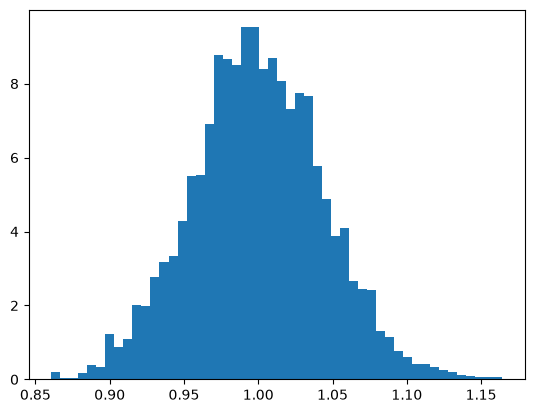

In [23]:
# теперь строю гистограмму полученных средних
plt.hist(daily_means, bins=50, density=True)
plt.show()

**Вывод:**
На гистограмме видно, что получился ровный симметричный колокол. Так происходит потому что я усредняю по 500 значений, случайные выбросы сглаживаются, и среднее начинает вести себя как нормальная величина. В этом и заключается суть центральной предельной теоремы.

# 3. Мини-кейс про кнопку

## 3.1. Сделал в другом формате

## 3.2. Проверить симуляцией

In [25]:
n_group = 5000
n_sim = 10000
p_true = 0.0325  # предполагаю, что кнопка ни на что не влияет

diffs = []
for _ in range(n_sim):
    group_a = np.random.binomial(n_group, p_true)
    group_b = np.random.binomial(n_group, p_true)
    diffs.append(group_b/n_group - group_a/n_group) # разница между двух конверсий

diffs = np.array(diffs)

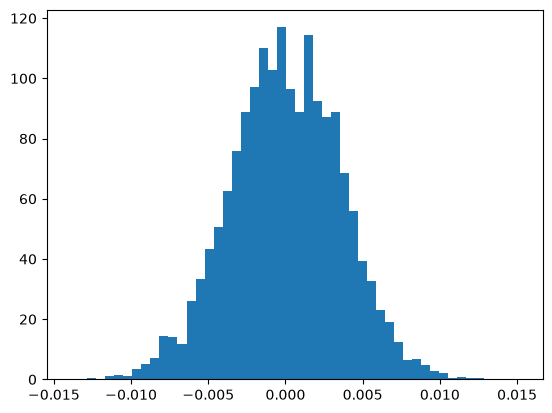

In [27]:
# гистограмма разниц
plt.hist(diffs, bins=50, density=True)
plt.show()

In [28]:
# проверяю на случайность
print((diffs >= 0.003).mean())

0.2053


**Вывод:**
На гистограмме видно, что разницы конверсий легли в симметричный колокол около нуля, также посчитано, как часто случайно получается разница 0.3 п.п. или больше и получилось около 20%, а это означает, что если бы кнопка ни на что не влияла, такая разница все равно появилась бы в каждом пятом эксперименте, поэтому разница в 0.3 п.п. это шум, а не эффект.

## 3.3. Выбросы во времени сессий

In [37]:
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

bound_3s = x.mean() + 3 * x.std(ddof=1) # правило трех сигм
p25, p75 = np.percentile(x, [25, 75]) # перцентили
bound_pct = p75 + 1.5 * (p75 - p25)

print(f"{bound_3s:.2f}, {bound_pct:.2f}")

54.50, 10.50


In [36]:
outliers_3s = x[x > bound_3s] # выбросы по правилам трех сигм
outliers_pct = x[x > bound_pct] # выбросы по перцентилям

print(outliers_3s, outliers_pct)

[] [52]


**Вывод:**
Правило трех сигм верхнюю границу поставило на 54.50, поэтому значение 52 выбросом не признало, а перцентили поставили границу на 10.50 и значение 52 в выбросы попало.

Лучше сработал метод перцентилей, потому что данные имеют длинный правый хвост, так как большинство значений маленькие, а 52 сильно выбивается. По правилу трех сигм граница считается через среднее и стандартное отклонение, а сам выброс сильно раздувает и среднее и отклонение, из-за чего граница смещается далеко вправо за пределы самого выброса, а перцентили зависят от порядка значений и не так сильно реагируют на величину одного выброса, поэтому граница остается адекватной и выброс находится.